# 25.43 Laboratorio de Procesamiento de Señales — TP3 Beamforming y dirección de arribo

## Apuntar sin mover nada

Al comienzo del curso planteamos el problema de Starlink: un panel plano que atiende a miles
de usuarios sin partes móviles, apuntando **con sumas**. Este TP es ese problema, a tu escala:
un arreglo de sensores, una escena real, y los tres estimadores del curso — DAS, MVDR y MUSIC —
puestos a decir **de dónde viene** cada cosa.

Los laboratorios del módulo recorren la cadena sobre el arreglo sintético, y el taller del
17/11 la recorre sobre tu dataset. Lo que el TP agrega es llevarla a datos reales y hacerlo
**bien**: los parámetros elegidos con criterio, la incertidumbre medida, y la defensa escrita
de qué método usarías para tu escena.

---

## Qué se entrega

**Esta misma notebook, completada y corrida de arriba abajo**, más `dataset_doa.npz` y el script
que lo generó (`convertir.py`) junto a ella. La grabación original no hace falta: alcanza con
decir cuál es. No hay informe aparte: el análisis va en las celdas de markdown, al lado de la
figura que lo sostiene.

Antes de entregar, *Kernel → Restart & Run All*. Si no corre de punta a punta, no se corrige.

**Si usás inteligencia artificial** —ChatGPT, Claude, Copilot o cualquier otra—, anexá el
registro de **todas** las preguntas que le hiciste: completas, en orden y sin editar. Va en un
archivo aparte junto a la notebook (`registro_IA.md`).

## Cómo se evalúa

| Criterio | Peso |
|---|---|
| **Análisis crítico** | **40 %** |
| Corrección técnica | 30 % |
| Figuras | 15 % |
| Reproducibilidad | 15 % |

**El núcleo son las cinco partes.** El núcleo bien hecho es un 8; las extensiones suman por
encima.

> **Una advertencia sobre el método de trabajo.** Acá los parámetros son $\varepsilon$ (el
> loading), $p$ (el número de fuentes), la ventana de snapshots y la grilla de $\theta$. La
> manera equivocada es moverlos hasta que los picos queden lindos. La manera correcta es
> decidir con las reglas del curso —$K \gtrsim 2M$, los autovalores para $p$, el loading
> sobre el piso de ruido— y **decir qué regla usaste**. Se nota cuál de las dos hiciste.

## Las figuras

Ejes rotulados con unidades, y todo barrido angular en dB con su referencia dicha. Una figura
sin pie no argumenta: decora.

---

## Desde cuándo se puede hacer cada parte

| Parte | A partir del |
|---|---|
| 1. El arreglo y sus datos | **03/11** |
| 2. DAS: el barrido | **03/11** |
| 3. MVDR, y sus dos modos de falla | **10/11** |
| 4. MUSIC, y cuántas fuentes | **17/11** |
| 5. Los tres, comparados y defendidos | **17/11** |
| Extensiones | cada una dice la suya |

Es **a partir de**, no *recién en*. El taller del 17/11 se trabaja sobre esta notebook, con la
conversión hecha y las partes 1 a 3 ya corriendo: quedan cuatro días hasta la entrega, y son
para las partes 4 y 5 y la redacción — no para el arranque.

## Los datos

Un dataset **real** de arreglo de micrófonos, y la conversión a `dataset_doa.npz` con las
claves `X` (snapshots complejos $M \times K$, banda angosta), `d` (espaciado en $\lambda$) y
`descripcion`.

**Usá [LOCATA](https://zenodo.org/record/3630471), tarea 2, del conjunto de desarrollo**
(`dev.zip`, 6,2 GB; grabaciones 1 y 3): varios parlantes fijos, un arreglo fijo, 48 kHz y unos
0,5 s de reverberación. Citalo como pide [su página](https://locata.lms.tf.fau.de/datasets/). Son
archivos `.wav` y `.txt`, con etiquetas de actividad de voz para quedarte con los tramos en que
suena la fuente.

El arreglo DICIT de LOCATA contiene cuatro **ULA**:

| Espaciado | Micrófonos, en orden | $M$ | $d = \lambda/2$ en |
|---|---|---|---|
| 4 cm | 5, 6, 7, 9, 10 | 5 | 4,3 kHz |
| 8 cm | 4, 5, 7, 10, 11 | 5 | 2,1 kHz |
| 16 cm | 3, 4, 7, 11, 12 | 5 | 1,07 kHz |
| 32 cm | 1, 2, 3, 7, 12, 13, 14 | 7 | 536 Hz |

**Cuál usar, y a qué frecuencia, es parte del trabajo:** más apertura resuelve mejor, pero pide
frecuencias más bajas y aleja el campo lejano.

La verdad son las posiciones medidas. Con $\hat{\mathbf{e}}$ el versor
del último sensor de tu subarreglo al primero, y $\hat{\mathbf{u}}$ el versor del centro del
subarreglo a la fuente, $\sin\theta = \hat{\mathbf{u}} \cdot \hat{\mathbf{e}}$. **Estimá primero
y compará después.**

La celda de carga trae además el **generador sintético de cátedra** — el de los laboratorios.
No reemplaza al dataset real: sirve para **validar tu cadena** (con verdad conocida) antes de
soltarla sobre datos reales, y como red de seguridad si el dataset se resiste. Si terminás
entregando sobre el sintético, decilo y explicá qué se resistió: se corrige igual, con ese
contexto.

> **La banda angosta es tu responsabilidad.** Los datasets reales son de banda ancha: elegí
> una frecuencia de trabajo, y armá los snapshots complejos ahí. La STFT es la herramienta:
> cada ventana, en el bin de esa frecuencia, es un snapshot.
> Documentá $f$, el ancho, y el $d/\lambda$ resultante — el error más común del TP vive acá.

Un punto de partida para `convertir.py`. El largo y el salto los elegís y los defendés vos:

```python
import numpy as np
from scipy.signal import stft


def snapshots_stft(x, fs, f_trabajo, largo, salto):
    """x: M×N real, un sensor por fila, en el orden del subarreglo."""
    f, _, Z = stft(x, fs=fs, nperseg=largo, noverlap=largo - salto, axis=1)
    b = np.argmin(np.abs(f - f_trabajo))
    return Z[:, b, :], f[b]


# X, f = snapshots_stft(x, fs, f_trabajo, largo, salto)
# np.savez("dataset_doa.npz", X=X, d=d_metros * f / 343, descripcion="LOCATA, tarea 2, ...")
```


In [1]:
# inline y no widget: la entrega tiene que renderizar sola para quien la corrija
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (11, 3.6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

GRADOS = np.linspace(-90, 90, 1441)


def steering(theta_deg, M, d):
    return np.exp(-2j * np.pi * np.arange(M) * d * np.sin(np.deg2rad(theta_deg)))


print("Listo.")

Listo.


In [2]:
def cargar(ruta="dataset_doa.npz"):
    """Tu dataset, convertido: X (M×K complejo), d (en λ), descripcion."""
    datos = np.load(ruta)
    return datos["X"], float(datos["d"]), str(datos.get("descripcion", ruta))


def generar_ula(thetas, snrs_db, M=12, d=0.5, K=200, semilla=2543):
    """El generador sintético de cátedra: fuentes incorreladas + ruido blanco."""
    rng = np.random.default_rng(semilla)
    X = np.sqrt(0.5) * (rng.standard_normal((M, K)) + 1j * rng.standard_normal((M, K)))
    for theta, snr_db in zip(thetas, snrs_db):
        pot = 10 ** (snr_db / 10)
        s = np.sqrt(pot / 2) * (rng.standard_normal(K) + 1j * rng.standard_normal(K))
        X += np.outer(steering(theta, M, d), s)
    return X


# para validar la cadena: verdad conocida
X_val = generar_ula([-30, 10, 45], [8, 5, 10])

# el dataset del TP (generado por convertir.py):
X, D_LAMBDA, DESCRIPCION = cargar()
print(DESCRIPCION, X.shape)

LOCATA (Löllmann et al., 2018), tarea 2, grabación 1, arreglo DICIT, subarreglo de 8 cm (micrófonos [4, 5, 7, 10, 11]). f = 2015.6 Hz (bin de 46.9 Hz), d/λ = 0.470. STFT Hann de 1024 muestras con salto de 512; 222 de 592 ventanas, las que tienen activos los parlantes [3, 4]. (5, 222)


In [15]:
# Funciones compartidas por las partes 2 a 5, adaptadas de las clases 14 a 16
from scipy.signal import find_peaks


def covarianza(X):
    """R estimada a partir de los K snapshots (columnas de X)."""
    return X @ X.conj().T / X.shape[1]


def posiciones_ula(M, d, sensor=None, corrimiento=0.0, escala=1.0):
    """Posiciones de los sensores en λ según el modelo. Por defecto, el ULA ideal.
    sensor/corrimiento: corre un sensor esa fracción de λ; escala: error relativo en d."""
    pos = np.arange(M) * d * escala
    if sensor is not None:
        pos[sensor] += corrimiento
    return pos


def matriz_steering(M, d, grados=GRADOS, posiciones=None):
    """Un vector de dirección por columna, uno por cada θ de la grilla.
    Con posiciones=None es el steering del setup; si no, el de ese modelo del arreglo."""
    if posiciones is None:
        return np.array([steering(th, M, d) for th in grados]).T
    return np.exp(-2j * np.pi * np.outer(posiciones, np.sin(np.deg2rad(grados))))


def das(R, d, grados=GRADOS, posiciones=None):
    """Periodograma espacial: a^H R a / M², para cada θ."""
    M = R.shape[0]
    A = matriz_steering(M, d, grados, posiciones)
    return np.real(np.sum(A.conj() * (R @ A), axis=0)) / M**2


def piso_ruido(R, p):
    """Media de los M − p autovalores más chicos de R."""
    autovalores = np.sort(np.linalg.eigvalsh(R))
    return np.mean(autovalores[: R.shape[0] - p])


def mvdr(R, d, eps=0.0, grados=GRADOS, posiciones=None):
    """Capon: 1 / (a^H (R + εI)⁻¹ a), para cada θ."""
    M = R.shape[0]
    A = matriz_steering(M, d, grados, posiciones)
    Ri = np.linalg.inv(R + eps * np.eye(M))
    return 1 / np.real(np.sum(A.conj() * (Ri @ A), axis=0))


def music(R, d, p, grados=GRADOS, posiciones=None):
    """Pseudoespectro: 1 / ||E_n^H a||², con E_n los M − p autovectores de ruido."""
    M = R.shape[0]
    _, V = np.linalg.eigh(R)                 # autovalores de menor a mayor
    ruido = V[:, : M - p]
    A = matriz_steering(M, d, grados, posiciones)
    return 1 / np.linalg.norm(ruido.conj().T @ A, axis=0) ** 2


def a_db(P):
    """Barrido en dB respecto de su propio máximo."""
    return 10 * np.log10(P / P.max())


def picos(P, n, grados=GRADOS):
    """Los θ de los n picos más altos del barrido, ordenados."""
    idx, _ = find_peaks(P)
    mejores = idx[np.argsort(P[idx])[::-1][:n]]
    return np.sort(grados[mejores])


def potencia_db(P, theta, grados=GRADOS):
    """Valor del barrido en la dirección θ, en dB absolutos (sin normalizar)."""
    return 10 * np.log10(P[np.argmin(np.abs(grados - theta))])


def doa_por_bloques(X, estimador, n_fuentes, n_bloques, tolerancia):
    """Parte X en bloques contiguos de snapshots y estima las DOA en cada uno.
    estimador(R) devuelve un barrido. Cada pico se asocia a la DOA de referencia
    (la de todos los snapshots) más cercana; si ninguno cae a menos de `tolerancia`
    grados, esa fuente queda NaN en ese bloque."""
    referencia = picos(estimador(covarianza(X)), n_fuentes)
    doas = np.full((n_bloques, n_fuentes), np.nan)
    for b, Xb in enumerate(np.array_split(X, n_bloques, axis=1)):
        encontrados = picos(estimador(covarianza(Xb)), n_fuentes)
        for j, ref in enumerate(referencia):
            if encontrados.size:
                cerca = encontrados[np.argmin(np.abs(encontrados - ref))]
                if abs(cerca - ref) < tolerancia:
                    doas[b, j] = cerca
    return referencia, doas

---

# Parte 1 — El arreglo y sus datos

> **A partir del 03/11**

Antes de ningún estimador: **qué mediste**.

**Qué hay que hacer.**

1. Documentá el arreglo: qué subarreglo elegiste y por qué, $M$, espaciado físico, y el
   $d/\lambda$ a tu frecuencia de trabajo. Si $d > \lambda/2$, decilo ya: tus barridos van a
   tener réplicas, y conviene saber dónde antes de interpretarlas. `steering` mide $\theta$
   desde la normal al arreglo, con $\theta > 0$ del lado del primer sensor.
2. Armá los snapshots de banda angosta en `convertir.py`, y justificá acá la ventana: cuántos
   son, cuán separados,
   y si la escena se puede suponer **quieta** durante ese tramo — es la estacionariedad de
   este módulo.
3. Formá $\hat{\mathbf{R}}$ y mirala: diagonal (¿algún sensor muerto o desbalanceado?),
   traza, y el espectro de autovalores. Guardá ese gráfico: la parte 4 lo retoma.
4. **Validá la cadena sobre el sintético** (`X_val`, verdad en el código) antes de soltarla
   sobre el dataset: si tu barrido no clava −30°, 10° y 45° ahí, no va a clavar nada en el
   dato real.

**Qué hay que responder.**

- ¿Cuánto vale $K/M$?
- ¿Qué apertura tenés en $\lambda$, y qué resolución de Rayleigh implica?
- ¿Se sostienen las dos hipótesis? Banda angosta, y campo lejano: compará la distancia a cada
  parlante con tu apertura.

frecuencia de trabajo  f = 2015.6 Hz   →   λ = 17.02 cm
espaciado              d = 8 cm = 0.470 λ   (sin réplicas de grating)
sensores y snapshots   M = 5, K = 222 de 592 ventanas   →   K/M = 44   (regla K ≳ 2M = 10)
apertura               M·d = 2.35 λ   →   Rayleigh ≈ 24.4°
campo lejano           2L²/λ = 1.20 m   (L = 32 cm);   parlantes a [1.42 1.49] m
banda angosta          L/c = 0.93 ms   contra   1/Δf = 21.3 ms

potencia por micrófono [4, 5, 7, 10, 11], en dB respecto de la media: [ 0.8  1.2  1.1 -6.1 -0.1]
traza de R: 5.514e-07   (suma de autovalores: 5.514e-07)
autovalores, en dB respecto del menor: [19.3 13.   5.9  2.6  0. ]
p = 2: el autovalor 2 está 9.5 dB sobre el piso; ε = 1.103e-07


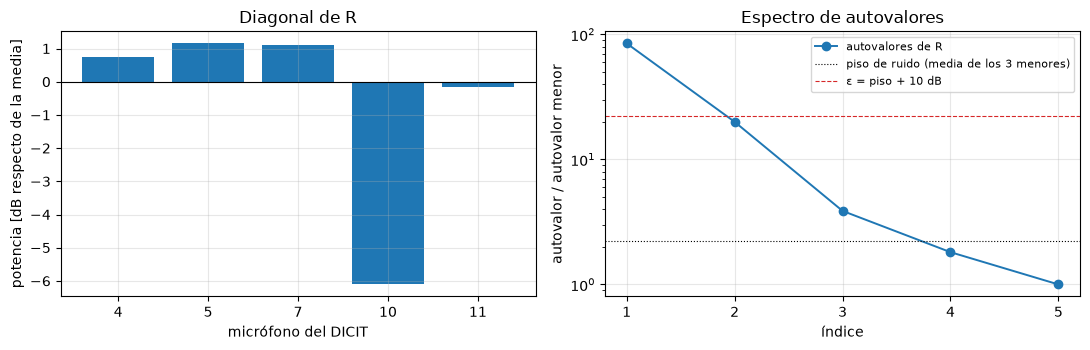

In [4]:
# Parte 1 — el arreglo, los snapshots y la R estimada
# Las variables que se definen acá (R, M, K, P_FUENTES, EPS) las usan todas las partes siguientes.
meta = np.load("dataset_doa.npz")
F_TRABAJO, D_METROS, C_SONIDO = float(meta["f"]), float(meta["d_metros"]), float(meta["c"])
MICROFONOS = [int(m) for m in meta["microfonos"]]

M, K = X.shape
lam = C_SONIDO / F_TRABAJO
apertura = M * D_LAMBDA                               # en λ, como en las clases 14 y 16
largo = (M - 1) * D_METROS                            # largo físico entre el primer y el último sensor
rayleigh = np.rad2deg(1 / apertura)
campo_lejano = 2 * largo**2 / lam

print(f"frecuencia de trabajo  f = {F_TRABAJO:.1f} Hz   →   λ = {lam * 100:.2f} cm")
print(f"espaciado              d = {D_METROS * 100:.0f} cm = {D_LAMBDA:.3f} λ   "
      f"({'sin' if D_LAMBDA <= 0.5 else 'CON'} réplicas de grating)")
print(f"sensores y snapshots   M = {M}, K = {K} de {int(meta['ventanas_totales'])} ventanas   →   "
      f"K/M = {K / M:.0f}   (regla K ≳ 2M = {2 * M})")
print(f"apertura               M·d = {apertura:.2f} λ   →   Rayleigh ≈ {rayleigh:.1f}°")
print(f"campo lejano           2L²/λ = {campo_lejano:.2f} m   (L = {largo * 100:.0f} cm);   "
      f"parlantes a {np.round(meta['distancias'], 2)} m")
print(f"banda angosta          L/c = {largo / C_SONIDO * 1e3:.2f} ms   contra   "
      f"1/Δf = {1e3 * int(meta['largo']) / int(meta['fs']):.1f} ms")

# La R estimada: diagonal, traza y autovalores
R = covarianza(X)
potencia_sensor = np.real(np.diag(R))
autovalores = np.sort(np.linalg.eigvalsh(R))[::-1]
diag_db = 10 * np.log10(potencia_sensor / potencia_sensor.mean())

print(f"\npotencia por micrófono {MICROFONOS}, en dB respecto de la media: {np.round(diag_db, 1)}")
print(f"traza de R: {np.real(np.trace(R)):.3e}   (suma de autovalores: {autovalores.sum():.3e})")
print(f"autovalores, en dB respecto del menor: {np.round(10 * np.log10(autovalores / autovalores[-1]), 1)}")

P_FUENTES = 2                                         # dos parlantes activos en los snapshots elegidos;
                                                      # la Parte 4 lo contrasta con los autovalores
piso = piso_ruido(R, P_FUENTES)
EPS = 10 * piso                                       # loading: 10 dB sobre el piso de ruido
print(f"p = {P_FUENTES}: el autovalor {P_FUENTES} está "
      f"{10 * np.log10(autovalores[P_FUENTES - 1] / piso):.1f} dB sobre el piso; ε = {EPS:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar([str(m) for m in MICROFONOS], diag_db, color="C0")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xlabel("micrófono del DICIT")
axes[0].set_ylabel("potencia [dB respecto de la media]")
axes[0].set_title("Diagonal de R")
axes[1].semilogy(np.arange(1, M + 1), autovalores / autovalores[-1], "o-", lw=1.4, label="autovalores de R")
axes[1].axhline(piso / autovalores[-1], color="k", ls=":", lw=0.8,
                label=f"piso de ruido (media de los {M - P_FUENTES} menores)")
axes[1].axhline(EPS / autovalores[-1], color="C3", ls="--", lw=0.8, label="ε = piso + 10 dB")
axes[1].set_xticks(np.arange(1, M + 1))
axes[1].set_xlabel("índice")
axes[1].set_ylabel("autovalor / autovalor menor")
axes[1].set_title("Espectro de autovalores")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

DAS    picos en [-30.125  10.     45.   ] °
MVDR   picos en [-30.  10.  45.] °
MUSIC  picos en [-30.  10.  45.] °
piso de ruido 1.03, ε = 10.27


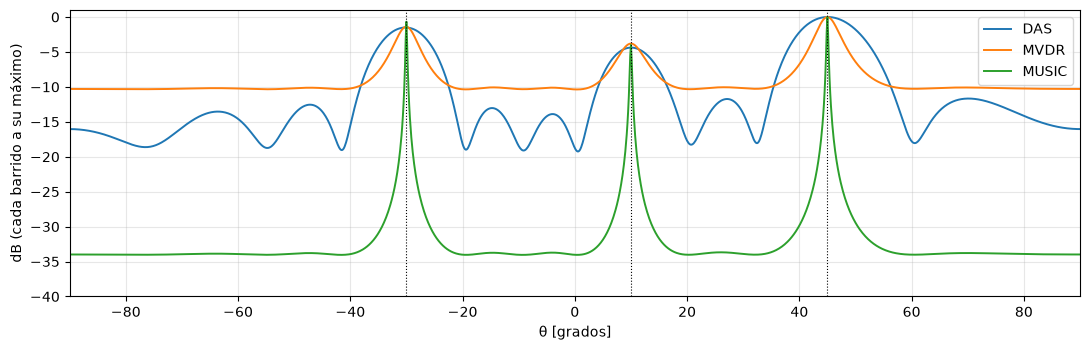

In [5]:
# Parte 1 — punto 4: Validación de la cadena sobre el sintético: la verdad es −30°, 10° y 45°
VERDAD_VAL = [-30, 10, 45]
M_val, d_val, p_val = X_val.shape[0], 0.5, 3

R_val = covarianza(X_val)
eps_val = 10 * piso_ruido(R_val, p_val)      # 10 dB sobre el piso de ruido
barridos_val = {
    "DAS": das(R_val, d_val),
    "MVDR": mvdr(R_val, d_val, eps=eps_val),
    "MUSIC": music(R_val, d_val, p_val),
}

for nombre, P in barridos_val.items():
    print(f"{nombre:6s} picos en {picos(P, p_val)} °")
print(f"piso de ruido {piso_ruido(R_val, p_val):.2f}, ε = {eps_val:.2f}")

fig, ax = plt.subplots()
for nombre, P in barridos_val.items():
    ax.plot(GRADOS, a_db(P), lw=1.4, label=nombre)
for th in VERDAD_VAL:
    ax.axvline(th, color="k", ls=":", lw=0.8)
ax.set_xlim(-90, 90)
ax.set_ylim(-40, 1)
ax.set_xlabel("θ [grados]")
ax.set_ylabel("dB (cada barrido a su máximo)")
ax.legend()
plt.tight_layout()
plt.show()

*Tu análisis de la parte 1, acá.*
### Análisis — El arreglo y sus datos

**Geometría y elección del subarreglo.** 

Se trabajó con un subarreglo de 5 micrófonos (4, 5, 7, 10 y 11) del arreglo DICIT, con un espaciamiento uniforme de 8 cm. Esta elección permite trabajar a una frecuencia cercana a 2 kHz sin introducir réplicas espaciales (*grating lobes*), ya que el espaciamiento resulta menor que media longitud de onda.

A la frecuencia de trabajo obtenida, $f = 2015.6$ Hz, la longitud de onda es $\lambda = 17.02$ cm, por lo que:

$$
\frac{d}{\lambda} = \frac{8}{17.02} \approx 0.470
$$

Al ser $d < \lambda/2$, no aparecen réplicas del patrón dentro del rango angular de interés. La apertura efectiva informada es $M d = 2.35\lambda$, lo que implica una resolución angular de Rayleigh aproximada de $24.4^\circ$. Esto establece una limitación para distinguir fuentes cercanas: cuanto mayor sea la apertura, mejor será la resolución angular.

**Snapshots y condición de banda angosta.**

Se utilizó una STFT con ventana Hann de 1024 muestras y un salto de 512 muestras, equivalente a ventanas de aproximadamente 21.3 ms separadas 10.7 ms. De las 592 ventanas disponibles, se conservaron 222, correspondientes a los intervalos en los que ambos parlantes estaban activos simultáneamente según sus indicadores VAD.

Por lo tanto:

$$
\frac{K}{M} = \frac{222}{5} = 44.4
$$

Se dispone de una cantidad de snapshots ampliamente superior a la regla orientativa $K \geq 2M = 10$, lo que permite estimar la matriz de correlación con una cantidad razonable de observaciones. Cabe aclarar que, al existir un solapamiento del 50% entre ventanas, los snapshots no son completamente independientes.

La hipótesis de banda angosta también se sostiene. El retardo máximo de propagación a través de la apertura es:

$$
\frac{L}{c} = 0.93\text{ ms}
$$

mientras que la escala temporal asociada al ancho de un bin es:

$$
\frac{1}{\Delta f} = 21.3\text{ ms}
$$

Como el retardo es considerablemente menor, podemos considerar que la señal conserva aproximadamente la misma fase relativa entre sensores dentro de la banda analizada, justificando el modelo de banda angosta.

**Condición de campo lejano.**

Para verificar la validez de esta hipótesis se calcula la distancia aproximada de Fraunhofer:

$$
R_{FF} = \frac{2L^2}{\lambda} = 1.20\text{ m}
$$

Las distancias de los parlantes al centro del subarreglo son 1.42 m y 1.49 m, respectivamente. Ambas superan el límite estimado, por lo que la condición de campo lejano se considera razonablemente satisfecha. Esto permite modelar las ondas incidentes como aproximadamente planas sobre el arreglo.

**Matriz de correlación y estado de los sensores.**

Se construyó la matriz de correlación espacial $R$ a partir de los snapshots seleccionados. Al inspeccionar su diagonal, se observa que las potencias de los micrófonos 4, 5, 7, 10 y 11, expresadas en dB respecto de la media, son:

$$
[0.8,\ 1.2,\ 1.1,\ -6.1,\ -0.1]\text{ dB}
$$

Se destaca el micrófono 10, cuya potencia está aproximadamente 6.1 dB por debajo de la media. Si bien esto evidencia un cierto desbalance entre canales que conviene tener presente, no alcanza por sí solo para concluir que el sensor esté muerto o no funcione.

La traza de la matriz es:

$$
\operatorname{tr}(R) = 5.514 \times 10^{-7}
$$

Este valor coincide con la suma de sus autovalores, verificando la consistencia de la descomposición espectral.

El espectro presenta dos autovalores dominantes respecto del piso de ruido. En particular, el segundo autovalor se encuentra aproximadamente 9.5 dB por encima del piso estimado. Esto es consistente con la presencia de dos fuentes activas y justifica la elección de $p=2$ para el análisis posterior de MUSIC.

**Validación previa con datos sintéticos.**

Antes de trabajar con las mediciones reales de LOCATA, se verificó la cadena completa de procesamiento utilizando una escena sintética de tres fuentes, ubicadas en $-30^\circ$, $10^\circ$ y $45^\circ$.

Los tres métodos implementados (DAS, MVDR y MUSIC) identificaron picos en:

$$
[-30.125^\circ,\ 10^\circ,\ 45^\circ]
$$

La coincidencia con las direcciones de referencia permite validar la construcción de las firmas espaciales, el convenio de signos, el barrido angular y la implementación de los estimadores.

Esta validación es importante porque permite descartar errores de implementación antes de interpretar los resultados obtenidos con los datos reales, donde ya no conocemos las direcciones de llegada de antemano.

**Conclusión.**

El subarreglo seleccionado permite trabajar a aproximadamente 2 kHz cumpliendo razonablemente las hipótesis de banda angosta y campo lejano, sin introducir réplicas espaciales. La cantidad de snapshots disponibles resulta suficiente para estimar la matriz de correlación, aunque se observa un desbalance de potencia en uno de los sensores que deberá tenerse presente al interpretar los resultados.

Finalmente, la validación sintética confirmó que los tres estimadores reproducen correctamente las direcciones de referencia, dejando preparada la cadena de procesamiento para analizar las mediciones reales.

---

# Parte 2 — DAS: el barrido

> **A partir del 03/11**

El periodograma espacial, sobre tu escena.

**Qué hay que hacer.**

1. El barrido DAS completo, en dB, con la grilla de $\theta$ declarada.
2. Marcá los picos que interpretás como fuentes, y el ancho de cada uno contra el Rayleigh de
   tu apertura: ¿son fuentes, o lóbulos laterales de otra?
3. Si tu $d/\lambda$ lo permite, mostrá (o descartá con la cuenta) las réplicas de grating.

**Qué hay que responder.**

- ¿Cuántas fuentes *afirmarías* con DAS solo, y con qué duda?
- ¿Qué limita acá: la apertura, el ruido, o los lóbulos laterales?

In [1]:
# Parte 2 — el barrido DAS sobre la escena
P_das = das(R, D_LAMBDA)
das_db = a_db(P_das)
paso_grilla = GRADOS[1] - GRADOS[0]


def ancho_3db(P_db, i):
    """Ancho a −3 dB del pico en el índice i, en grados (recorre la grilla hacia cada lado).
    Si el barrido no cae 3 dB antes del borde, el ancho no está definido: NaN."""
    izq = i
    while izq > 0 and P_db[izq] > P_db[i] - 3:
        izq -= 1
    der = i
    while der < len(P_db) - 1 and P_db[der] > P_db[i] - 3:
        der += 1
    if P_db[izq] > P_db[i] - 3 or P_db[der] > P_db[i] - 3:
        return np.nan
    return GRADOS[der] - GRADOS[izq]


# todos los máximos locales, del más alto al más bajo
idx, _ = find_peaks(das_db)
idx = idx[np.argsort(das_db[idx])[::-1]]
print(f"grilla de θ: {GRADOS[0]:.0f}° a {GRADOS[-1]:.0f}° de a {paso_grilla:.3f}°;  Rayleigh ≈ {rayleigh:.1f}°")
print(f"{'θ':>9s} {'nivel':>9s} {'ancho −3 dB':>13s}")
for i in idx:
    ancho = ancho_3db(das_db, i)
    print(f"{GRADOS[i]:8.2f}° {das_db[i]:7.1f} dB " + (f"{ancho:10.1f}°" if np.isfinite(ancho) else "  no cae 3 dB"))

# patrón del arreglo apuntado al pico más alto: lo que DAS vería si hubiera una sola fuente ahí
theta_max = GRADOS[idx[0]]
patron = np.abs(steering(theta_max, M, D_LAMBDA).conj() @ matriz_steering(M, D_LAMBDA)) ** 2 / M**2
patron_db = 10 * np.log10(patron)

# réplicas de grating: sin θ_g = sin θ0 ± λ/d tiene que caer en [−1, 1] para existir
print(f"\nλ/d = {1 / D_LAMBDA:.2f}: |sin θ0 ± λ/d| ≥ {1 / D_LAMBDA - 1:.2f} > 1 para todo θ0  →  sin réplicas")

fig, ax = plt.subplots()
ax.plot(GRADOS, das_db, lw=1.4, label="DAS")
ax.plot(GRADOS, patron_db, "k--", lw=0.9, label=f"patrón de una sola fuente en {theta_max:.1f}°")
for i in idx[:P_FUENTES]:
    ax.plot(GRADOS[i], das_db[i], "o", color="C3")
    ax.annotate(f"{GRADOS[i]:.1f}°", (GRADOS[i], das_db[i]), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set_xlim(-90, 90)
ax.set_ylim(-25, 1)
ax.set_xlabel("θ [grados]")
ax.set_ylabel("potencia [dB respecto del máximo]")
ax.set_title(f"DAS — Rayleigh ≈ {rayleigh:.0f}°")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

NameError: name 'das' is not defined

*Tu análisis de la parte 2, acá.*

### Análisis — DAS: el barrido espacial

**Resolución angular y detección de fuentes.**

El barrido se realizó entre $-90^\circ$ y $90^\circ$, con una resolución de grilla de $0.125^\circ$. Esta discretización es suficientemente fina respecto de la resolución angular propia del arreglo, por lo que la limitación principal no está en la grilla sino en la apertura física.

El máximo del barrido aparece en $28.62^\circ$, normalizado a 0 dB, con un ancho a $-3$ dB de aproximadamente $35.1^\circ$. Este ancho supera la resolución de Rayleigh estimada para nuestra apertura, de aproximadamente $24.4^\circ$, lo que evidencia que el lóbulo principal es relativamente ancho y limita la capacidad de separar fuentes cercanas.

Además, aparecen dos máximos locales en $-76.75^\circ$ (-6.5 dB) y $-26.50^\circ$ (-8 dB). Sin embargo, ninguno presenta un ancho a $-3$ dB bien definido dentro del barrido. Al compararlos con el patrón teórico de una única fuente apuntada a $28.62^\circ$, se observa que son compatibles con la estructura de lóbulos laterales del arreglo, por lo que no los interpretamos directamente como fuentes adicionales.

Por lo tanto, utilizando únicamente DAS, afirmaríamos la presencia de una fuente dominante alrededor de $28.6^\circ$, aunque con cierta incertidumbre: los máximos secundarios pueden generar ambigüedad y el ancho del lóbulo principal podría estar ocultando fuentes cercanas. No podemos asegurar que exista una única fuente a partir de este resultado.

**Réplicas espaciales (*grating lobes*).**

A la frecuencia de trabajo, el espaciamiento entre sensores es $d/\lambda = 0.470$, por lo que se cumple la condición $d < \lambda/2$. Equivalentemente:

$$
\frac{\lambda}{d} = 2.13
$$

Para que aparezca una réplica debería cumplirse:

$$
\left|\sin\theta_0 \pm \frac{\lambda}{d}\right|\leq 1
$$

Sin embargo, incluso en el caso más favorable, el valor mínimo es $2.13-1=1.13$, superior a 1. Por lo tanto, no existen soluciones angulares para las réplicas de grating dentro del dominio físico y podemos descartarlas.

**¿Qué limita la resolución en este caso?**

La principal limitación para distinguir fuentes cercanas es la apertura del arreglo, que determina el ancho del lóbulo principal y su resolución de Rayleigh. Por otro lado, los lóbulos laterales introducen máximos secundarios que pueden confundirse con fuentes adicionales. El ruido también afecta el piso de detección, aunque los resultados no indican que sea la limitación dominante en este caso.

En consecuencia, DAS permite identificar una dirección dominante, pero no ofrece suficiente capacidad de resolución para asegurar cuántas fuentes cercanas componen la escena. Esto motiva el uso de métodos adaptativos y de subespacio en las siguientes partes.

---

# Parte 3 — MVDR, y sus dos modos de falla

> **A partir del 10/11**

El barrido de Capon sobre tu $\hat{\mathbf{R}}$ — con sus dos modos de falla vigilados,
porque acá la $\mathbf{R}$ es estimada y el steering es el de *tu* modelo del arreglo.

**Qué hay que hacer.**

1. El barrido MVDR con diagonal loading. Elegí $\varepsilon$ como en el laboratorio de MVDR,
   10 dB sobre el piso de ruido, que leés en los autovalores chicos de tu $\hat{\mathbf{R}}$.
   Mostrá el barrido con y sin loading.
2. **Snapshots:** partí tu registro y mostrá cómo cambia el barrido con $K/2$ y con $K$.
   ¿Estás del lado bueno de la regla $2M$?
3. **Desajuste:** corré en tu modelo del arreglo la posición de un sensor, una fracción de
   $\lambda$. En la dirección de cada fuente, compará en dB absolutos la potencia
   que dan DAS y MVDR con el modelo correcto y con el perturbado. Es el
   contraejemplo de la clase, sobre tu dato: el desajuste que importa es el de *tu*
   calibración, no el del sintético.

**Qué hay que responder.**

- ¿Qué ganó MVDR sobre DAS en tu escena, y dónde perdió?
- ¿Tu escena tiene interferentes fuertes que justifiquen los nulos, o MVDR está de adorno?
- ¿Qué le pasa al barrido de MVDR si el error es del 2 % en $d$, y por qué?

ε = 1.103e-07   (piso 1.103e-08;   autovalores [38.   9.   1.7  0.8  0.4] × piso)
DAS             picos en [-76.75   28.625] °
MVDR sin carga  picos en [28.125] °
MVDR con carga  picos en [-72.875  28.625] °


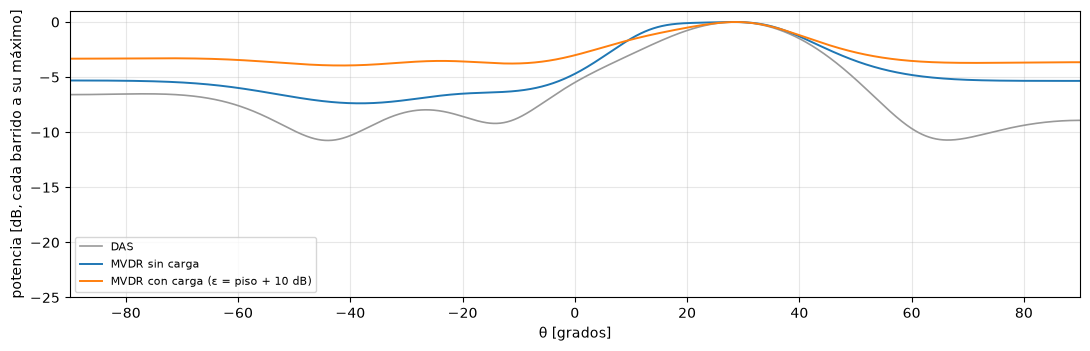

In [7]:
# Parte 3 — punto 1: MVDR con y sin loading (ε de la Parte 1: 10 dB sobre el piso de ruido)
P_mvdr_sin = mvdr(R, D_LAMBDA)
P_mvdr = mvdr(R, D_LAMBDA, eps=EPS)

print(f"ε = {EPS:.3e}   (piso {piso:.3e};   autovalores {np.round(autovalores / piso, 1)} × piso)")
for nombre, P in [("DAS", P_das), ("MVDR sin carga", P_mvdr_sin), ("MVDR con carga", P_mvdr)]:
    print(f"{nombre:15s} picos en {picos(P, P_FUENTES)} °")

fig, ax = plt.subplots()
ax.plot(GRADOS, a_db(P_das), lw=1.2, color="0.6", label="DAS")
ax.plot(GRADOS, a_db(P_mvdr_sin), lw=1.4, label="MVDR sin carga")
ax.plot(GRADOS, a_db(P_mvdr), lw=1.4, label="MVDR con carga (ε = piso + 10 dB)")
ax.set_xlim(-90, 90)
ax.set_ylim(-25, 1)
ax.set_xlabel("θ [grados]")
ax.set_ylabel("potencia [dB, cada barrido a su máximo]")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

K/2 = 111 snapshots, contra la regla 2M = 10
MVDR sin carga  primera mitad (K/2)  picos en [-21.75  21.75] °
MVDR sin carga  segunda mitad (K/2)  picos en [29.5] °
MVDR sin carga  todos (K)            picos en [28.125] °
MVDR con carga  primera mitad (K/2)  picos en [-23.125  19.375] °
MVDR con carga  segunda mitad (K/2)  picos en [-74.75   29.875] °
MVDR con carga  todos (K)            picos en [-72.875  28.625] °


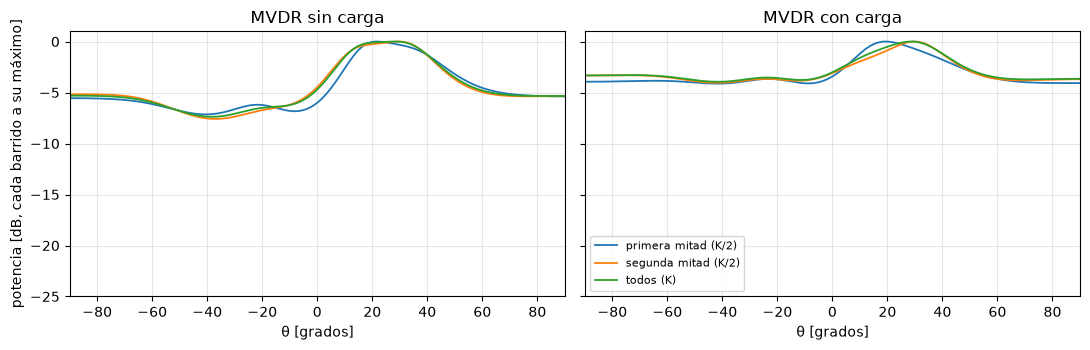

In [8]:
# Parte 3 — punto 2: el barrido MVDR con K/2 y con K snapshots
mitades = {"primera mitad (K/2)": X[:, : K // 2], "segunda mitad (K/2)": X[:, K // 2 :], "todos (K)": X}
print(f"K/2 = {K // 2} snapshots, contra la regla 2M = {2 * M}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (titulo, con_carga) in zip(axes, [("MVDR sin carga", False), ("MVDR con carga", True)]):
    for nombre, Xs in mitades.items():
        Rs = covarianza(Xs)
        eps_s = 10 * piso_ruido(Rs, P_FUENTES) if con_carga else 0.0
        P = mvdr(Rs, D_LAMBDA, eps=eps_s)
        ax.plot(GRADOS, a_db(P), lw=1.3, label=nombre)
        print(f"{titulo:15s} {nombre:20s} picos en {picos(P, P_FUENTES)} °")
    ax.set_title(titulo)
    ax.set_xlim(-90, 90)
    ax.set_ylim(-25, 1)
    ax.set_xlabel("θ [grados]")
axes[0].set_ylabel("potencia [dB, cada barrido a su máximo]")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

direcciones (MUSIC, p = 2): [14.875 30.875] °
ganancias relativas medidas: [ 0.8  1.2  1.1 -6.1 -0.1] dB
dirección 14.9°
   DAS             correcto  -73.7 dB   sensor 1 +0.1λ:  +0.0 dB   d con +2 %:  +0.1 dB   ganancias corregidas:  +0.1 dB
   MVDR sin carga  correcto  -81.3 dB   sensor 1 +0.1λ:  +0.2 dB   d con +2 %:  +0.0 dB   ganancias corregidas:  +4.1 dB
   MVDR con carga  correcto  -73.1 dB   sensor 1 +0.1λ:  +0.1 dB   d con +2 %:  +0.0 dB   ganancias corregidas:  +0.7 dB
dirección 30.9°
   DAS             correcto  -71.9 dB   sensor 1 +0.1λ:  +0.2 dB   d con +2 %:  -0.0 dB   ganancias corregidas:  +0.3 dB
   MVDR sin carga  correcto  -80.9 dB   sensor 1 +0.1λ:  +1.2 dB   d con +2 %:  -0.0 dB   ganancias corregidas:  +1.7 dB
   MVDR con carga  correcto  -72.1 dB   sensor 1 +0.1λ:  +0.4 dB   d con +2 %:  -0.0 dB   ganancias corregidas:  +0.8 dB


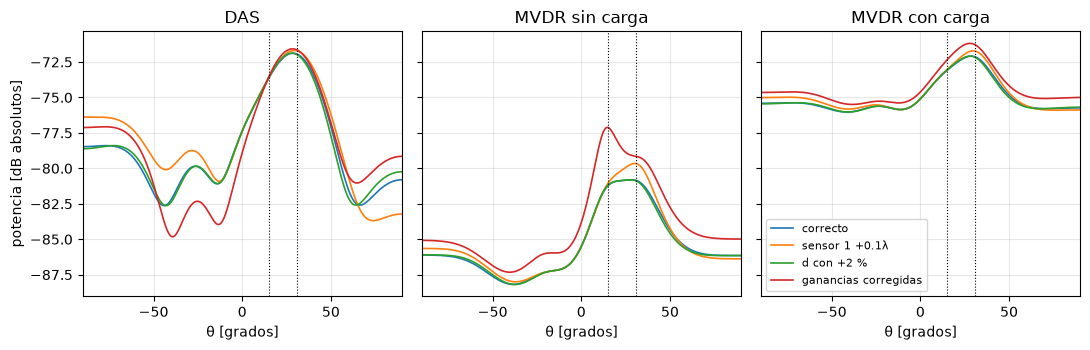

In [9]:
# Parte 3 — punto 3: desajuste entre el modelo del arreglo y el arreglo real
# DAS y MVDR funden las fuentes cercanas: las direcciones donde se mide salen de MUSIC con p = P_FUENTES
DIRECCIONES = picos(music(R, D_LAMBDA, P_FUENTES), P_FUENTES)
SENSOR, CORRIMIENTO = 1, 0.1                         # corre el segundo sensor un décimo de λ

modelos = {
    "correcto": posiciones_ula(M, D_LAMBDA),
    f"sensor {SENSOR} +{CORRIMIENTO}λ": posiciones_ula(M, D_LAMBDA, sensor=SENSOR, corrimiento=CORRIMIENTO),
    "d con +2 %": posiciones_ula(M, D_LAMBDA, escala=1.02),
}
# el desajuste que sí se midió: la ganancia de cada micrófono (diagonal de R, Parte 1).
# Corregirla es dividir cada canal por su ganancia relativa, con el modelo geométrico correcto.
g = np.sqrt(potencia_sensor / potencia_sensor.mean())
R_cal = R / np.outer(g, g)
EPS_cal = 10 * piso_ruido(R_cal, P_FUENTES)
modelos["ganancias corregidas"] = posiciones_ula(M, D_LAMBDA)

def usa(mod):
    """La R y el ε que corresponden a cada modelo."""
    return (R_cal, EPS_cal) if mod == "ganancias corregidas" else (R, EPS)

metodos = {
    "DAS": lambda Rm, eps, pos: das(Rm, D_LAMBDA, posiciones=pos),
    "MVDR sin carga": lambda Rm, eps, pos: mvdr(Rm, D_LAMBDA, posiciones=pos),
    "MVDR con carga": lambda Rm, eps, pos: mvdr(Rm, D_LAMBDA, eps=eps, posiciones=pos),
}
barridos = {(m, mod): fn(*usa(mod), pos) for m, fn in metodos.items() for mod, pos in modelos.items()}

print(f"direcciones (MUSIC, p = {P_FUENTES}): {DIRECCIONES} °")
print(f"ganancias relativas medidas: {np.round(20 * np.log10(g), 1)} dB")
for th in DIRECCIONES:
    print(f"dirección {th:.1f}°")
    for m in metodos:
        valores = [potencia_db(barridos[(m, mod)], th) for mod in modelos]
        cambios = "   ".join(f"{mod}: {v - valores[0]:+5.1f} dB" for mod, v in zip(list(modelos)[1:], valores[1:]))
        print(f"   {m:15s} correcto {valores[0]:6.1f} dB   {cambios}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, m in zip(axes, metodos):
    for mod in modelos:
        ax.plot(GRADOS, 10 * np.log10(barridos[(m, mod)]), lw=1.2, label=mod)
    for th in DIRECCIONES:
        ax.axvline(th, color="k", ls=":", lw=0.8)
    ax.set_title(m)
    ax.set_xlim(-90, 90)
    ax.set_xlabel("θ [grados]")
axes[0].set_ylabel("potencia [dB absolutos]")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

*Tu análisis de la parte 3, acá.*

---

# Parte 4 — MUSIC, y cuántas fuentes

> **A partir del 17/11**

La pregunta que MUSIC obliga a contestar antes de contestar la tuya.

**Qué hay que hacer.**

1. El espectro de autovalores de la parte 1, ahora leído: elegí $p$ y defendé la elección.
2. El pseudoespectro MUSIC con tu $p$ — y con $p - 1$ y $p + 1$ al lado: ¿cuán sensible es lo
   que afirmás?
3. **DOA con incertidumbre:** partí tus snapshots en bloques, estimá las DOA en cada bloque, y
   reportá media y dispersión por fuente. Un $\theta$ sin incertidumbre no es una medición.
   Compará recién entonces con el $\theta$ que sale de las posiciones medidas.
4. El control de sanidad del ULA: el arreglo no distingue adelante de atrás, y lo que mide es
   $\sin\theta$ respecto de su eje: una fuente a otra altura cae en el mismo cono. Decí qué
   ambigüedad tiene tu geometría y cómo la tratás al reportar.

**Qué hay que responder.**

- ¿El pseudoespectro te dio picos donde DAS no veía nada? ¿Les creés? ¿Por qué?
- Si tus fuentes fueran coherentes (multipath), ¿qué le pasaría a esta parte? Una oración —
  la extensión B lo desarrolla.

autovalores, en dB respecto del menor: [19.3 13.   5.9  2.6  0. ]
salto entre autovalores consecutivos [dB]: [6.3 7.1 3.3 2.6]
el salto más grande está entre el 2.º y el 3.º;  p elegido: 2
MUSIC con p = 1: picos en [28.625] °
MUSIC con p = 2: picos en [14.875 30.875] °
MUSIC con p = 3: picos en [14.375 36.875] °


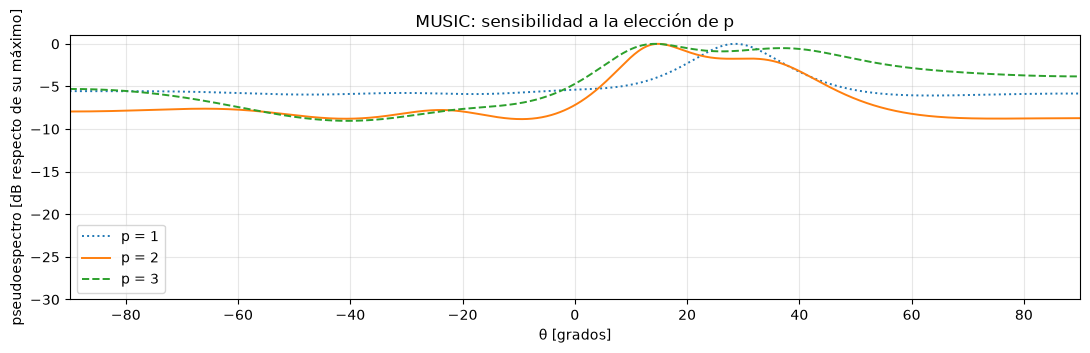

In [10]:
# Parte 4 — puntos 1 y 2: cuántas fuentes, y MUSIC con p − 1, p y p + 1
saltos_db = 10 * np.log10(autovalores[:-1] / autovalores[1:])
print(f"autovalores, en dB respecto del menor: {np.round(10 * np.log10(autovalores / autovalores[-1]), 1)}")
print(f"salto entre autovalores consecutivos [dB]: {np.round(saltos_db, 1)}")
print(f"el salto más grande está entre el {np.argmax(saltos_db) + 1}.º y el {np.argmax(saltos_db) + 2}.º;  "
      f"p elegido: {P_FUENTES}")

fig, ax = plt.subplots()
for p, estilo in zip([P_FUENTES - 1, P_FUENTES, P_FUENTES + 1], [":", "-", "--"]):
    P = music(R, D_LAMBDA, p)
    ax.plot(GRADOS, a_db(P), estilo, lw=1.4, label=f"p = {p}")
    print(f"MUSIC con p = {p}: picos en {picos(P, p)} °")
ax.set_xlim(-90, 90)
ax.set_ylim(-30, 1)
ax.set_xlabel("θ [grados]")
ax.set_ylabel("pseudoespectro [dB respecto de su máximo]")
ax.set_title("MUSIC: sensibilidad a la elección de p")
ax.legend()
plt.tight_layout()
plt.show()

5 bloques de ~44 snapshots (regla 2M = 10); un pico cuenta si cae a menos de 8.0° de la DOA con todos los snapshots
DOA en cada bloque [°]:
[[15.1 33.6]
 [15.  36.5]
 [16.8  nan]
 [13.5 30.8]
 [11.9  nan]]
fuente 1:    14.4° ±  1.8°   (todos los snapshots: 14.9°;  bloques sin pico: 0)
fuente 2:    33.6° ±  2.9°   (todos los snapshots: 30.9°;  bloques sin pico: 2)


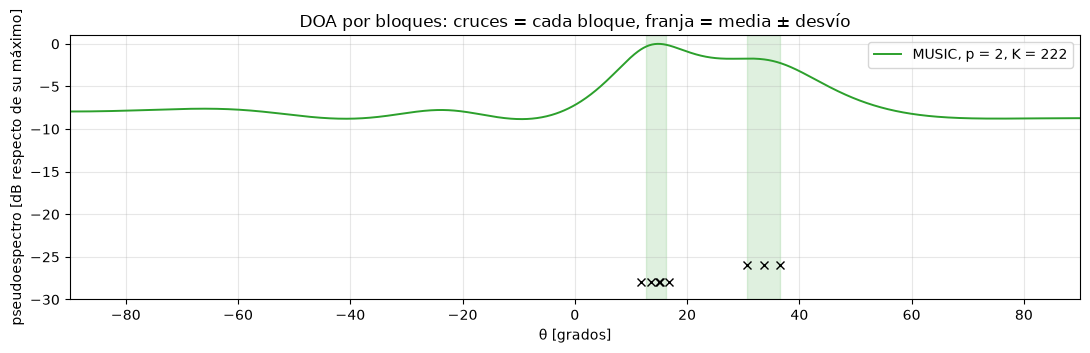

In [11]:
# Parte 4 — punto 3: DOA con incertidumbre, partiendo los snapshots en bloques contiguos
N_BLOQUES = 5
P_music = music(R, D_LAMBDA, P_FUENTES)
DOA_MUSIC = picos(P_music, P_FUENTES)
tolerancia = min(rayleigh, np.min(np.diff(DOA_MUSIC))) / 2     # medio Rayleigh o media separación

ref, doas_bloques = doa_por_bloques(X, lambda Rb: music(Rb, D_LAMBDA, P_FUENTES),
                                    n_fuentes=P_FUENTES, n_bloques=N_BLOQUES, tolerancia=tolerancia)
media = np.nanmean(doas_bloques, axis=0)
desvio = np.nanstd(doas_bloques, axis=0, ddof=1)

print(f"{N_BLOQUES} bloques de ~{K // N_BLOQUES} snapshots (regla 2M = {2 * M}); "
      f"un pico cuenta si cae a menos de {tolerancia:.1f}° de la DOA con todos los snapshots")
print(f"DOA en cada bloque [°]:\n{np.round(doas_bloques, 1)}")
for j in range(P_FUENTES):
    print(f"fuente {j + 1}:  {media[j]:6.1f}° ± {desvio[j]:4.1f}°   "
          f"(todos los snapshots: {ref[j]:.1f}°;  bloques sin pico: {np.sum(np.isnan(doas_bloques[:, j]))})")

fig, ax = plt.subplots()
ax.plot(GRADOS, a_db(P_music), lw=1.4, color="C2", label=f"MUSIC, p = {P_FUENTES}, K = {K}")
for j in range(P_FUENTES):
    ax.axvspan(media[j] - desvio[j], media[j] + desvio[j], color="C2", alpha=0.15)
    ax.plot(doas_bloques[:, j], np.full(N_BLOQUES, -28 + 2 * j), "x", color="k")
ax.set_xlim(-90, 90)
ax.set_ylim(-30, 1)
ax.set_xlabel("θ [grados]")
ax.set_ylabel("pseudoespectro [dB respecto de su máximo]")
ax.set_title("DOA por bloques: cruces = cada bloque, franja = media ± desvío")
ax.legend()
plt.tight_layout()
plt.show()

In [12]:
# Parte 4 — punto 3, después de estimar: la comparación con la verdad geométrica
# sin θ = û·ê, con ê del último sensor al primero y û del centro del subarreglo a cada parlante (convertir.py)
VERDAD = np.sort(meta["verdad"])
for j in range(P_FUENTES):
    error = media[j] - VERDAD[j]
    print(f"fuente {j + 1}:  estimada {media[j]:6.1f}° ± {desvio[j]:4.1f}°   verdad {VERDAD[j]:6.1f}°   "
          f"error {error:+5.1f}°  ({abs(error) / desvio[j]:.1f} desvíos)")

fuente 1:  estimada   14.4° ±  1.8°   verdad   17.6°   error  -3.1°  (1.7 desvíos)
fuente 2:  estimada   33.6° ±  2.9°   verdad   33.2°   error  +0.4°  (0.1 desvíos)


*Tu análisis de la parte 4, acá.*

---

# Parte 5 — Los tres, comparados y defendidos

> **A partir del 17/11**

Esta parte tiene poco código, y es la que más pesa.

**Qué hay que hacer.**

1. Los tres barridos en los mismos ejes, cada uno a su máximo, con las DOA de la parte 4
   marcadas.
2. La tabla de tu escena: para cada método, qué estimó, qué supuso, y dónde se notó ese
   supuesto **en tus datos**.
3. **Resolución y ruido, con el generador**, donde conocés la verdad: dos fuentes de igual
   potencia, con tu $M$ y tu $K$. Barré la separación, para varias SNR, y mostrá desde qué
   separación cada método da dos picos. Usá varias semillas y decí cuántas.

**Qué hay que responder.**

- Para *tu* escena y *tu* pregunta: ¿cuál de los tres usarías, y **qué estás suponiendo** al
  elegirlo? Es la pregunta del cierre de estimación espectral, ahora cerrando el curso.
- En el punto 3, ¿cuál método depende más de la SNR? ¿Te sorprende, viendo qué supone cada uno?
- ¿Qué medirías distinto si pudieras repetir la adquisición?

> Las elecciones distintas pueden estar bien las dos. Lo que se corrige es el argumento,
> apoyado en las figuras de las partes 2 a 4.

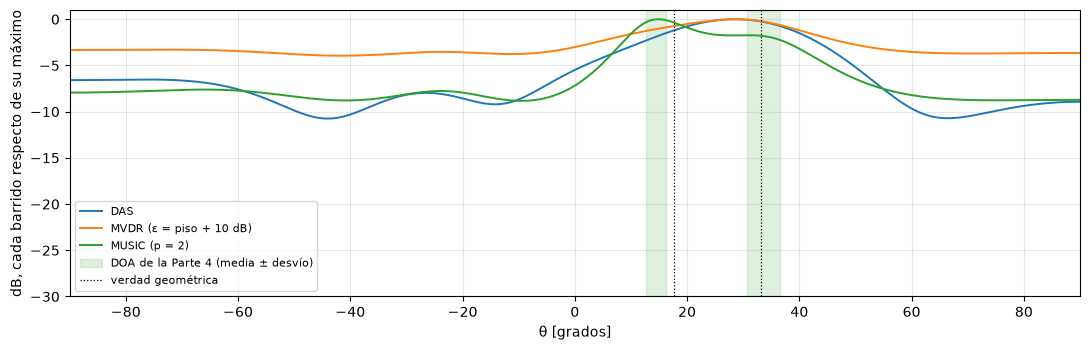

,picos [°],fuentes separadas (de 2)
método,,
DAS,"[-76.8, 28.6]",1
MVDR (ε = piso + 10 dB),"[-72.9, 28.6]",1
MUSIC (p = 2),"[14.9, 30.9]",2


In [13]:
# Parte 5 — puntos 1 y 2: los tres barridos sobre la misma R, y lo que estimó cada uno
import pandas as pd
from IPython.display import display

barridos_finales = {
    "DAS": P_das,
    f"MVDR (ε = piso + 10 dB)": P_mvdr,
    f"MUSIC (p = {P_FUENTES})": P_music,
}

fig, ax = plt.subplots()
for nombre, P in barridos_finales.items():
    ax.plot(GRADOS, a_db(P), lw=1.4, label=nombre)
for j in range(P_FUENTES):
    ax.axvspan(media[j] - desvio[j], media[j] + desvio[j], color="C2", alpha=0.15,
               label="DOA de la Parte 4 (media ± desvío)" if j == 0 else None)
for j, th in enumerate(VERDAD):
    ax.axvline(th, color="k", ls=":", lw=0.9, label="verdad geométrica" if j == 0 else None)
ax.set_xlim(-90, 90)
ax.set_ylim(-30, 1)
ax.set_xlabel("θ [grados]")
ax.set_ylabel("dB, cada barrido respecto de su máximo")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# qué estimó cada método: sus picos, y cuántos caen cerca de una DOA de la Parte 4
filas = []
for nombre, P in barridos_finales.items():
    est = picos(P, P_FUENTES)
    separadas = sum(np.any(np.abs(est - m) < tolerancia) for m in media)
    filas.append({"método": nombre, "picos [°]": np.round(est, 1).tolist(),
                  f"fuentes separadas (de {P_FUENTES})": separadas})
display(pd.DataFrame(filas).set_index("método"))

3 SNR × 40 separaciones × 50 semillas en 12 s
M = 5, K = 222, d = 0.470λ — Rayleigh ≈ 24.4°
   SNR       DAS      MVDR     MUSIC
   0 dB       22°       21°        9°
  10 dB       22°       18°        5°
  20 dB       22°       12°        3°


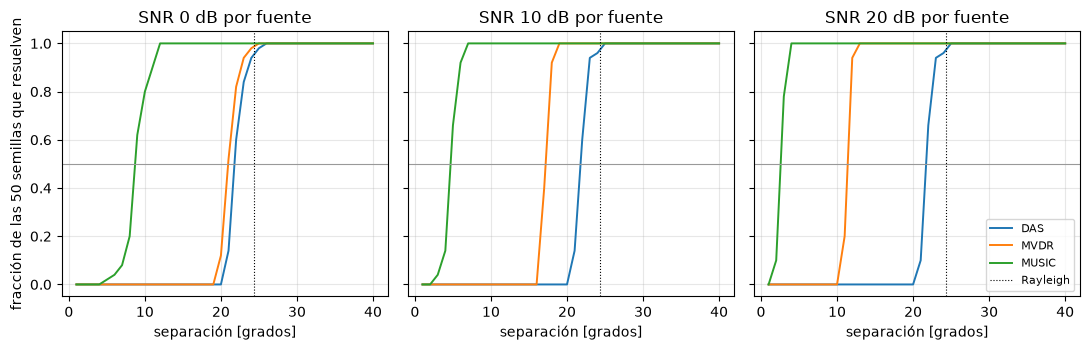

In [14]:
# Parte 5.3 — resolución contra separación y SNR, con el generador de cátedra
import time

M_RES, K_RES = X.shape                # el M y el K de la escena del TP
D_RES = D_LAMBDA
SEPARACIONES = np.arange(1, 41, 1.0)  # grados entre las dos fuentes
SNRS_RES = [0, 10, 20]                # dB por fuente, contra ruido de potencia 1
SEMILLAS = 50
CENTRO = 0.0                          # las fuentes en CENTRO ± Δ/2: el caso más favorable (broadside)

pos_res = posiciones_ula(M_RES, D_RES)          # con posiciones explícitas, el steering sale vectorizado
estimadores_res = {
    "DAS": lambda R: das(R, D_RES, posiciones=pos_res),
    "MVDR": lambda R: mvdr(R, D_RES, eps=10 * piso_ruido(R, 2), posiciones=pos_res),
    "MUSIC": lambda R: music(R, D_RES, 2, posiciones=pos_res),
}


def resuelve(P, verdad, sep):
    """Dos picos, y cada uno a menos de media separación de su fuente."""
    est = picos(P, 2)
    return est.size == 2 and np.all(np.abs(est - np.sort(verdad)) < sep / 2)


t0 = time.perf_counter()
prob = {m: np.zeros((len(SNRS_RES), len(SEPARACIONES))) for m in estimadores_res}
for i, snr in enumerate(SNRS_RES):
    for j, sep in enumerate(SEPARACIONES):
        verdad = [CENTRO - sep / 2, CENTRO + sep / 2]
        for semilla in range(SEMILLAS):
            R_s = covarianza(generar_ula(verdad, [snr, snr], M=M_RES, d=D_RES, K=K_RES, semilla=semilla))
            for m, est in estimadores_res.items():
                prob[m][i, j] += resuelve(est(R_s), verdad, sep) / SEMILLAS
print(f"{len(SNRS_RES)} SNR × {len(SEPARACIONES)} separaciones × {SEMILLAS} semillas "
      f"en {time.perf_counter() - t0:.0f} s")

# separación mínima a la que cada método resuelve en al menos la mitad de las semillas
rayleigh = np.rad2deg(1 / (M_RES * D_RES))
print(f"M = {M_RES}, K = {K_RES}, d = {D_RES:.3f}λ — Rayleigh ≈ {rayleigh:.1f}°")
print(f"{'SNR':>6s}" + "".join(f"{m:>10s}" for m in estimadores_res))
for i, snr in enumerate(SNRS_RES):
    fila = []
    for m in estimadores_res:
        ok = np.nonzero(prob[m][i] >= 0.5)[0]
        fila.append(f"{SEPARACIONES[ok[0]]:9.0f}°" if ok.size else "      > 40°")
    print(f"{snr:4d} dB" + "".join(fila))

fig, axes = plt.subplots(1, len(SNRS_RES), figsize=(11, 3.6), sharey=True)
for ax, i in zip(axes, range(len(SNRS_RES))):
    for m in estimadores_res:
        ax.plot(SEPARACIONES, prob[m][i], lw=1.4, label=m)
    ax.axvline(rayleigh, color="k", ls=":", lw=0.8, label="Rayleigh")
    ax.axhline(0.5, color="0.6", lw=0.8)
    ax.set_title(f"SNR {SNRS_RES[i]} dB por fuente")
    ax.set_xlabel("separación [grados]")
axes[0].set_ylabel(f"fracción de las {SEMILLAS} semillas que resuelven")
axes[-1].legend(fontsize=8)
plt.tight_layout()
plt.show()

*Tu defensa, acá. Es la sección más importante de la entrega.*

---

# Extensiones

Suman por encima del núcleo. **Una hecha bien vale más que tres empezadas.**

**A. ESPRIT, sin barrer** · *a partir del 17/11*
Implementá ESPRIT sobre los dos subarreglos de tu ULA y compará sus DOA con las de MUSIC:
precisión, tiempo de cómputo, y qué pasa con la incertidumbre de la parte 4. ¿Cuándo conviene
el barrido de MUSIC, y cuándo no?

**B. El eco que rompe el subespacio** · *a partir del 17/11*
Modificá el generador para obtener dos fuentes **coherentes** (la misma
señal, retardada y atenuada — un multipath). Mostrá que MUSIC se rompe, aplicá spatial
smoothing, y mostrá la reparación y la apertura que se pierde. Después decí si tu dataset real puede tener este problema.

**C. El arreglo casero** · *libre*
Cuatro micrófonos (o cuatro celulares grabando a la vez), una regla, y palmas desde ángulos
medidos con cinta en el piso. Sincronizá por el pico, armá los snapshots, y localizá. El
protocolo y sus miserias —sincronía, $d/\lambda$, reverberación— valen tanto como el
resultado.

**D. La fuente que se mueve** · *a partir del 17/11*
Si tu dataset tiene una fuente móvil (o generala): DOA por ventanas deslizantes y la
trayectoria $\theta(t)$. ¿Qué ventana elegís, y qué compromiso estás jugando? — es el de la STFT,
en el plano ángulo-tiempo.

---

## Antes de entregar

- *Kernel → Restart & Run All*, y que corra entero — con `dataset_doa.npz` junto a la notebook.
- `convertir.py` junto a la notebook, con los parámetros que usaste.
- Todas las figuras con ejes rotulados, unidades y pie.
- Las celdas de análisis contestadas, no vacías. **Son el 40 %.**
- Nombres de los integrantes en la celda de abajo.

**Los seis errores que más aparecen.**

1. **El $d/\lambda$ equivocado.** El espaciado físico es fijo; $\lambda$ depende de la
   frecuencia de trabajo que elegiste. Documentala, y rehacé la cuenta si cambiás de banda.
2. Snapshots de banda ancha metidos en un modelo de banda angosta: los picos se corren y
   nadie sabe por qué. La conversión de la parte 1 es la mitad del TP.
3. Grilla de $\theta$ de 1° y DOA reportada con dos decimales: tu precisión no puede ser
   mejor que tu grilla ni que tu dispersión entre bloques.
4. $p$ elegido para que MUSIC muestre lo que esperabas, sin mirar los autovalores.
5. Comparar métodos con ventanas de snapshots distintas y atribuir la diferencia al método.
6. Reportar DOA sin incertidumbre, o sin decir la ambigüedad adelante-atrás del ULA.

---

**Grupo:**

**Integrantes:**

**Extensiones hechas:**